In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/smoke_detection_iot.csv')

In [3]:
df.head()

,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-null  float64
 14  CNT             62630 non-null  int64  
 15  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 7.6 MB


In [5]:
df = df.drop(['CNT', 'Unnamed: 0', 'UTC'], axis=1)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Temperature[C]  62630 non-null  float64
 1   Humidity[%]     62630 non-null  float64
 2   TVOC[ppb]       62630 non-null  int64  
 3   eCO2[ppm]       62630 non-null  int64  
 4   Raw H2          62630 non-null  int64  
 5   Raw Ethanol     62630 non-null  int64  
 6   Pressure[hPa]   62630 non-null  float64
 7   PM1.0           62630 non-null  float64
 8   PM2.5           62630 non-null  float64
 9   NC0.5           62630 non-null  float64
 10  NC1.0           62630 non-null  float64
 11  NC2.5           62630 non-null  float64
 12  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(5)
memory usage: 6.2 MB


In [7]:
df['Fire Alarm'].value_counts()

Fire Alarm
1    44757
0    17873
Name: count, dtype: int64

<Axes: xlabel='Fire Alarm', ylabel='count'>

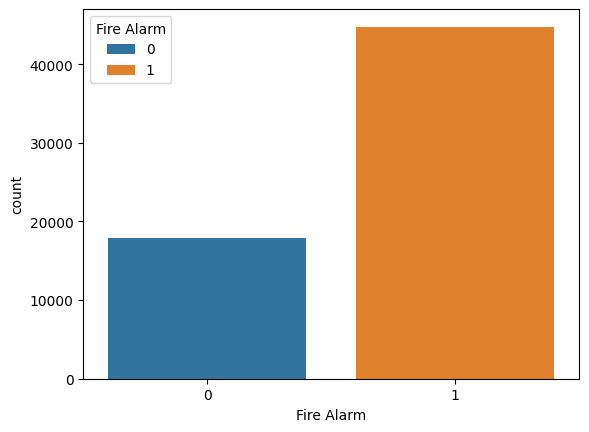

In [8]:
sns.countplot(x='Fire Alarm', data=df, hue='Fire Alarm')

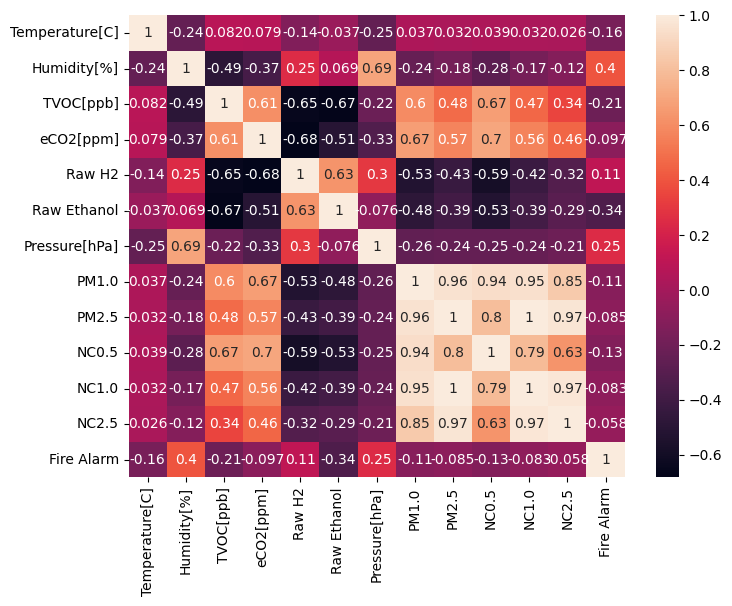

In [9]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True);

In [10]:
np.abs(df.corr()['Fire Alarm']).sort_values().tail(6)

Temperature[C]    0.163902
TVOC[ppb]         0.214743
Pressure[hPa]     0.249797
Raw Ethanol       0.340652
Humidity[%]       0.399846
Fire Alarm        1.000000
Name: Fire Alarm, dtype: float64

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest

In [12]:
X = df.drop('Fire Alarm', axis=1)

In [13]:
y = df['Fire Alarm']

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104, stratify=y)

In [15]:
iso_forest = IsolationForest(contamination=0.01, random_state=104, n_jobs=-1, n_estimators=100)

In [16]:
mask = iso_forest.fit_predict(X_train)

In [17]:
X_train_clean = X_train[mask==1]
y_train_clean = y_train[mask==1]

In [18]:
X_train_clean.shape

(49602, 12)

In [19]:
X_train.shape

(50104, 12)

In [20]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, X_train.columns.tolist())
    ],
    remainder='passthrough'
)

In [22]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler_2', StandardScaler()),
    ('model', LogisticRegressionCV(Cs=5,
                                   cv=5,
                                  penalty='l2',
                                  solver='lbfgs',
                                  max_iter=1_000,
                                  n_jobs=-1,
                                  random_state=104,
                                   class_weight='balanced'))
])

In [23]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [24]:
%%time
pipe.fit(X_train_clean, y_train_clean)

CPU times: total: 391 ms
Wall time: 6.4 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [25]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [26]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [100.]


In [27]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [28]:
accuracy

0.9986428229283091

In [29]:
recall

0.9989945257513128

In [30]:
precision

0.9991061452513966

In [31]:
roc_auc_test

0.9999096870061007

In [32]:
roc_auc_train

0.9997422855343454

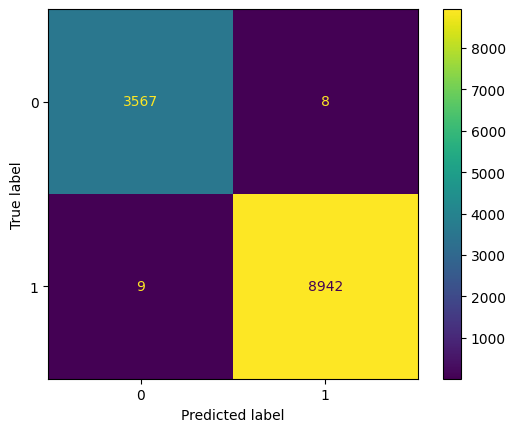

In [33]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test)

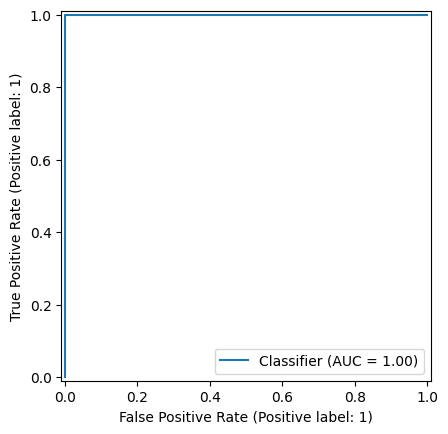

In [34]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba)

In [35]:
mask = iso_forest.fit_predict(X)

In [36]:
X_cleaned = X[mask==1]
y_cleaned = y[mask==1]

In [37]:
X.shape

(62630, 12)

In [38]:
X_cleaned.shape

(62003, 12)

In [39]:
%%time
pipe.fit(X_cleaned, y_cleaned)

CPU times: total: 1.05 s
Wall time: 5.71 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [56]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")
print(f"Лучшее значение l1_ratio: {best_final_model.l1_ratio_}")

Лучшее значение C: [0.0001]
Лучшее значение l1_ratio: [None]


In [41]:
y_full_proba = pipe.predict_proba(X_cleaned)[:, 1]

In [42]:
roc_auc_full = roc_auc_score(y_cleaned, y_full_proba)

In [43]:
roc_auc_full

0.957906799227551

In [44]:
smoke_test_data = {
    'Temperature[C]': [22.0, 45.5],
    'Humidity[%]': [45.0, 65.0], 
    'TVOC[ppb]': [0.0, 6500.0],
    'eCO2[ppm]': [350.0, 1500.0],
    'Raw H2': [13800.0, 12000.0],
    'Raw Ethanol': [21000.0, 17000.0],
    'Pressure[hPa]': [939.0, 941.5],
    'PM1.0': [1.2, 350.0],      
    'PM2.5': [0.0, 800.0],
    'NC0.5': [7.0, 2400.0],
    'NC1.0': [1.1, 550.0],
    'NC2.5': [0.02, 12.5]
}

In [45]:
test_df_smoke = pd.DataFrame(smoke_test_data)

In [46]:
test_df_smoke

,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5
0,22.0,45.0,0.0,350.0,13800.0,21000.0,939.0,1.2,0.0,7.0,1.1,0.02
1,45.5,65.0,6500.0,1500.0,12000.0,17000.0,941.5,350.0,800.0,2400.0,550.0,12.50


In [47]:
predictions = pipe.predict(test_df_smoke)
probabilities = pipe.predict_proba(test_df_smoke)

In [48]:
class_labels = {0: 'Все спокойно (Воздух чист)', 1: '🚨 ПОЖАР / ДЫМ! ВКЛЮЧЕНА СИРЕНА!'}

print("="*75)
print("🦾 ВЕРДИКТ МОДЕЛИ:")
print("="*75)

for i in range(2):
    pred_class = predictions[i]
    prob_0 = probabilities[i][0] * 100
    prob_1 = probabilities[i][1] * 100
    
    print(f"Сценарий №{i+1}:")
    print(f"  -> Вердикт Модели:          {class_labels[pred_class]}")
    print(f"  -> Вероятность класса 0 (пожар нет  / не включаем сирену): {prob_0:.2f}%")
    print(f"  -> Вероятность класса 1 (пожар есть /    включаем сирену): {prob_1:.2f}%")
    print("-"*75)

🦾 ВЕРДИКТ МОДЕЛИ:
Сценарий №1:
  -> Вердикт Модели:          Все спокойно (Воздух чист)
  -> Вероятность класса 0 (пожар нет  / не включаем сирену): 91.84%
  -> Вероятность класса 1 (пожар есть /    включаем сирену): 8.16%
---------------------------------------------------------------------------
Сценарий №2:
  -> Вердикт Модели:          🚨 ПОЖАР / ДЫМ! ВКЛЮЧЕНА СИРЕНА!
  -> Вероятность класса 0 (пожар нет  / не включаем сирену): 7.39%
  -> Вероятность класса 1 (пожар есть /    включаем сирену): 92.61%
---------------------------------------------------------------------------


In [49]:
class_percents = df['Fire Alarm'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 28.5%, 1: 71.5%


In [50]:
import json
import os

advanced_report = {
    "project": "Smoke Detection Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [51]:
from joblib import dump, load

In [52]:
dump(pipe, "model/smoke_detection_predict_logistic_regression_cv_2026_v1.pkl")

['model/smoke_detection_predict_logistic_regression_cv_2026_v1.pkl']

In [53]:
loaded_pipe = load("model/smoke_detection_predict_logistic_regression_cv_2026_v1.pkl")

In [54]:
predictions = loaded_pipe.predict(test_df_smoke)
probabilities = loaded_pipe.predict_proba(test_df_smoke)

In [55]:
class_labels = {0: 'Все спокойно (Воздух чист)', 1: '🚨 ПОЖАР / ДЫМ! ВКЛЮЧЕНА СИРЕНА!'}

print("="*75)
print("🦾 ВЕРДИКТ МОДЕЛИ:")
print("="*75)

for i in range(2):
    pred_class = predictions[i]
    prob_0 = probabilities[i][0] * 100
    prob_1 = probabilities[i][1] * 100
    
    print(f"Сценарий №{i+1}:")
    print(f"  -> Вердикт Модели:          {class_labels[pred_class]}")
    print(f"  -> Вероятность класса 0 (пожар нет  / не включаем сирену): {prob_0:.2f}%")
    print(f"  -> Вероятность класса 1 (пожар есть /    включаем сирену): {prob_1:.2f}%")
    print("-"*75)

🦾 ВЕРДИКТ МОДЕЛИ:
Сценарий №1:
  -> Вердикт Модели:          Все спокойно (Воздух чист)
  -> Вероятность класса 0 (пожар нет  / не включаем сирену): 91.84%
  -> Вероятность класса 1 (пожар есть /    включаем сирену): 8.16%
---------------------------------------------------------------------------
Сценарий №2:
  -> Вердикт Модели:          🚨 ПОЖАР / ДЫМ! ВКЛЮЧЕНА СИРЕНА!
  -> Вероятность класса 0 (пожар нет  / не включаем сирену): 7.39%
  -> Вероятность класса 1 (пожар есть /    включаем сирену): 92.61%
---------------------------------------------------------------------------
